# Diabetic Retinopathy using MobileNet 

## 1. Import library

In [ ]:
import tensorflow as tf
from tensorflow.keras import layers, models, Input
from tensorflow.keras.optimizers import Adam
import matplotlib.pyplot as plt
import numpy as np
import pickle
from sklearn.model_selection import train_test_split

In [ ]:
print('TensorFlow version:', tf.__version__)

TensorFlow version: 2.21.0


## 2. Load Data

In [ ]:
with open("../../../data/processed/aptos/sample_50/sample_dataset.pkl", "rb") as f:
    data = pickle.load(f)

In [ ]:
print("Keys:", data.keys())
print("Data shape:", data['data'].shape)
print("Labels:", data['labels'])
print("Classes:", data['class_names'])

Keys: dict_keys(['data', 'labels', 'class_names'])
Data shape: (250, 300, 300, 3)
Labels: [0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 2 2 2 2 2 2 2 2 2 2 2
 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2
 2 2 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3
 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4
 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4]
Classes: ['No_DR', 'Mild', 'Moderate', 'Severe', 'Proliferate_DR']


## 3. Data Preprocessing 

In [ ]:
X           = data['data']        # (N, 300, 300, 3)
y           = data['labels']      # (N,)
class_names = data['class_names'] # list 5 tên lớp

NUM_CLASSES = len(class_names)
IMG_SIZE    = X.shape[1]          # 300

print(f'Số mẫu: {len(X)} | Số lớp: {NUM_CLASSES} | Kích thước ảnh: {IMG_SIZE}x{IMG_SIZE}')

Số mẫu: 250 | Số lớp: 5 | Kích thước ảnh: 300x300


In [ ]:
x_train, x_test, y_train, y_test = train_test_split(
    X,y, test_size=0.2, random_state=42, stratify=y
)
print('Train:', x_train.shape, y_train.shape)

Train: (200, 300, 300, 3) (200,)


In [ ]:
y_train[:16]

In [ ]:
# Normalize
x_train = x_train.astype('float32') / 255.0
x_test  = x_test.astype('float32')  / 255.0

# One-hot encode
y_train = tf.keras.utils.to_categorical(y_train, NUM_CLASSES)
y_test  = tf.keras.utils.to_categorical(y_test,  NUM_CLASSES)

print('y_train shape:', y_train.shape)

y_train shape: (200, 5)


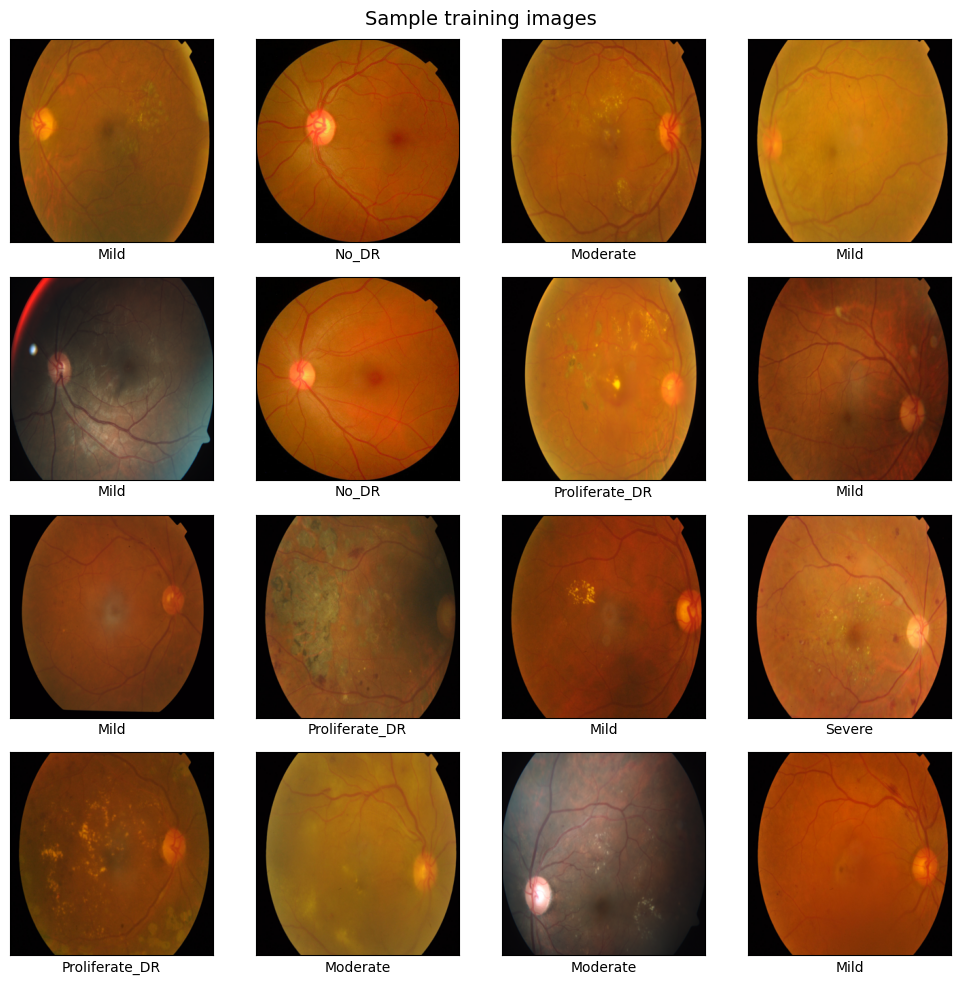

In [ ]:
# Xem thử 16 ảnh đầu
plt.figure(figsize=(10, 10))
for i in range(16):
    plt.subplot(4, 4, i + 1)
    plt.xticks([]); plt.yticks([]); plt.grid(False)
    plt.imshow(x_train[i])
    plt.xlabel(class_names[np.argmax(y_train[i])])
plt.suptitle('Sample training images', fontsize=14)
plt.tight_layout()
plt.show()

## 4. Xây dựng MobileNet v1

### Kiến trúc
```
Input (300×300×3)
  └─ Conv2D/s2          → 150×150×32
  └─ DW+PW ×13          → các stride=2 downsample
  └─ GlobalAvgPool      → 1×1×1024
  └─ Dropout(0.5)
  └─ Dense(NUM_CLASSES, softmax)
```

**Depthwise Separable Conv** = Depthwise Conv → BN → ReLU → Pointwise (1×1) → BN → ReLU

In [ ]:
def depthwise_separable_block(x, filters, strides=1):
    x = layers.DepthwiseConv2D(kernel_size=3, strides=strides, padding='same', use_bias=False)(x)
    x = layers.BatchNormalization()(x)
    x = layers.ReLU()(x)
    
    # Pointwise conv 
    x = layers.Conv2D(filters, kernel_size=1, padding='same', use_bias=False)(x)
    x = layers.BatchNormalization()(x)
    x = layers.ReLU()(x)
    return x 

In [ ]:
def build_mobilenet_v1(input_shape=(300, 300, 3), num_classes=5):
    inputs = Input(shape=input_shape)
    # Stem: standard conv 
    x = layers.Conv2D(32, kernel_size=3, strides=2, padding='same', use_bias=False)(inputs)
    x = layers.BatchNormalization()(x)
    x = layers.ReLU()(x)
    # → 150×150×32
    
    # 13 DW + PW blocks 
    dw_config = [
        (64,   1),
        (128,  2),
        (128,  1),
        (256,  2),
        (256,  1),
        (512,  2),
        (512,  1),  # ×5 lần
        (512,  1),
        (512,  1),
        (512,  1),
        (512,  1),
        (1024, 2),
        (1024, 1),
    ]
    for filters, stride in dw_config: 
        x = depthwise_separable_block(x, filters, stride)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.5)(x)
    outputs = layers.Dense(num_classes, activation='softmax')(x)
    return models.Model(inputs, outputs, name='MobileNetV1') 

In [ ]:
model = build_mobilenet_v1(input_shape=(IMG_SIZE, IMG_SIZE, 3), num_classes=NUM_CLASSES)
model.summary()

I0000 00:00:1784738504.203024    2022 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 1765 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 2050, pci bus id: 0000:01:00.0, compute capability: 8.6


Model: "MobileNetV1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 300, 300, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 150, 150, 32)   │           864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 150, 150, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu (ReLU)                    │ (None, 150, 150, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ depthwise_conv2d                │ (None, 150, 150, 32)   │           288 │
│ (DepthwiseConv2D)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 150, 150, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_1 (ReLU)                  │ (None, 150, 150, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 150, 150, 64)   │         2,048 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 150, 150, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_2 (ReLU)                  │ (None, 150, 150, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ depthwise_conv2d_1              │ (None, 75, 75, 64)     │           576 │
│ (DepthwiseConv2D)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 75, 75, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_3 (ReLU)                  │ (None, 75, 75, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 75, 75, 128)    │         8,192 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 75, 75, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_4 (ReLU)                  │ (None, 75, 75, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ depthwise_conv2d_2              │ (None, 75, 75, 128)    │         1,152 │
│ (DepthwiseConv2D)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 75, 75, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_5 (ReLU)                  │ (None, 75, 75, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 75, 75, 128)    │        16,384 │
├─────────────────────────────────┼────────────────────────┼─────────────

 Total params: 3,233,989 (12.34 MB)

 Trainable params: 3,212,101 (12.25 MB)

 Non-trainable params: 21,888 (85.50 KB)

## 5. Compile & Train 

In [ ]:
model.compile(
    optimizer=Adam(learning_rate=1e-3), 
    loss='categorical_crossentropy', 
    metrics=['accuracy']
)
# Callbacks 
callbacks = [
    tf.keras.callbacks.ModelCheckpoint(
        '../../../data/models/mobilenet_best.keras',
        monitor='val_accuracy', save_best_only=True, verbose=1
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor='val_loss', factor=0.5, patience=3, 
        min_lr=1e-6, verbose=1
    ),
    tf.keras.callbacks.EarlyStopping(
        monitor='val_loss', patience=7, 
        restore_best_weights=True, verbose=1
    )
]
history = model.fit(
    x_train,
    y_train, 
    epochs=20, 
    batch_size=8,
    validation_split=0.2,
    callbacks=callbacks,
    verbose=2
)

Epoch 1/20


I0000 00:00:1784738517.393179    4513 service.cc:153] XLA service 0x7537d8064270 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1784738517.393218    4513 service.cc:161]   StreamExecutor [0]: NVIDIA GeForce RTX 2050, Compute Capability 8.6 (Driver: 13.0.0; Runtime: 12.5.0; Toolkit: 12.5.0; DNN: 9.21.1)
I0000 00:00:1784738517.819883    4513 dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
I0000 00:00:1784738519.785036    4513 cuda_dnn.cc:461] Loaded cuDNN version 92101
I0000 00:00:1784738520.115877    4513 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_16682__.125
W0000 00:00:1784738537.893394    4513 bfc_allocator.cc:502] Allocator (GPU_0_bfc) ran out of memory trying to allocate 2.07GiB (rounded to 2226422272)requested by op 
If the cause is memory fragmentation maybe the environment variable 'TF_GPU_ALLOCATOR=cuda_malloc_async' will improv


Epoch 1: val_accuracy improved from None to 0.12500, saving model to ../../../data/models/mobilenet_best.keras

Epoch 1: finished saving model to ../../../data/models/mobilenet_best.keras
20/20 - 91s - 5s/step - accuracy: 0.2250 - loss: 1.8820 - val_accuracy: 0.1250 - val_loss: 1.6488 - learning_rate: 0.0010
Epoch 2/20

Epoch 2: val_accuracy did not improve from 0.12500
20/20 - 2s - 87ms/step - accuracy: 0.3000 - loss: 1.6248 - val_accuracy: 0.1250 - val_loss: 1.6463 - learning_rate: 0.0010
Epoch 3/20

Epoch 3: val_accuracy did not improve from 0.12500
20/20 - 2s - 80ms/step - accuracy: 0.3875 - loss: 1.4813 - val_accuracy: 0.1250 - val_loss: 1.7217 - learning_rate: 0.0010
Epoch 4/20

Epoch 4: val_accuracy did not improve from 0.12500
20/20 - 2s - 80ms/step - accuracy: 0.4062 - loss: 1.4368 - val_accuracy: 0.1250 - val_loss: 1.8003 - learning_rate: 0.0010
Epoch 5/20

Epoch 5: val_accuracy did not improve from 0.12500

Epoch 5: ReduceLROnPlateau reducing learning rate to 0.000500000023

## 6. Visualize Training

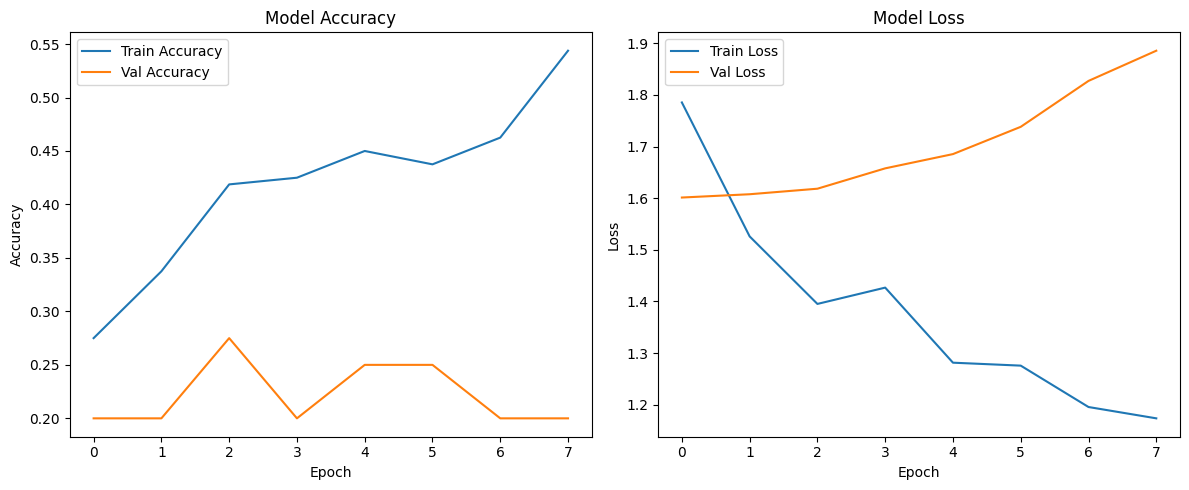

In [ ]:
plt.figure(figsize=(12,5))
plt.subplot(1,2,1)
plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Val Accuracy')
plt.title('Model Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history['loss'],     label='Train Loss')
plt.plot(history.history['val_loss'], label='Val Loss')
plt.title('Model Loss')
plt.xlabel('Epoch'); plt.ylabel('Loss'); plt.legend()

plt.tight_layout()
plt.show()

## 7. Evaluate on Test Set

In [ ]:
test_loss, test_acc = model.evaluate(x_test, y_test, verbose=0)
print(f'Test Loss: {test_loss:.4f}')
print(f'Test Accuracy: {test_acc:.4f}') 

Test Loss: 1.6167
Test Accuracy: 0.2000
